# Feature Extraction

Data representation plays a critical role in the performance of many machine learning methods in machine learning. The data representation of network traffic often determines the effectiveness of these models as much as the model itself. The wide range of novel events that network operators need to detect (e.g., attacks, malware, new applications, changes in traffic demands) introduces the possibility for a broad range of possible models and data representations.

[NetML](https://pypi.org/project/netml/) is an open-source tool and end-to-end pipeline for anomaly detection in network traffic. This notebook walks through the use of that library.

First, let us load the library.

In [2]:
import logging
logging.getLogger("scapy.runtime").setLevel(logging.ERROR)

from netml.pparser.parser import PCAP
from netml.utils.tool import dump_data, load_data

import pandas as pd

## Specify a Packet Capture File

Create a pcap data structure for which we would like to extract features. You could do this based on the packet capture files that we have been using in previous hands assignments. Any packet capture file will suffice, however.

You can define the minumum number of packets that you want to include in each flow.

In [3]:
pcap=PCAP(
'/home/frank/ml-systems/docs/notebooks/data/netflix.pcap',
flow_ptks_thres=10,
random_state=42,
verbose=10,
)

## Convert the Packet Capture Into Flows

Find the function in `netml` that converts the pcap file into flows. Examing the resulting data structure. What does it contain?

In [4]:
pcap.pcap2flows()

# The result is stored in pcap.flows
flows = pcap.flows

pcap_file: /home/frank/ml-systems/docs/notebooks/data/netflix.pcap
ith_packets: 0
ith_packets: 10000
ith_packets: 20000
ith_packets: 30000
ith_packets: 40000
ith_packets: 50000
ith_packets: 60000
ith_packets: 70000
ith_packets: 80000
ith_packets: 90000
ith_packets: 100000
ith_packets: 110000
ith_packets: 120000
ith_packets: 130000
ith_packets: 140000
len(flows): 275
total number of flows: 275. Num of flows < 10 pkts: 141, and >=10 pkts: 134 without timeout splitting.
kept flows: 134. Each of them has at least 10 pkts after timeout splitting.
flow_durations.shape: (134, 1)
        col_0
count 134.000
mean   96.917
std   133.751
min     2.686
25%    14.454
50%    23.419
75%   106.963
max   486.413
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   col_0   134 non-null    float64
dtypes: float64(1)
memory usage: 1.2 KB
None
0th_flow: len(pkts): 12
After split

## Explore the Flows

How many flows are in your data structure?

In [5]:
print(type(flows), len(flows))
print("Number of flows:", len(flows))

# Structure of one entry
flow_id, packets = flows[0]
print("Entry type:   ", type(flows[0]), "of length", len(flows[0]))
print("flow_id:      ", flow_id, " (src_ip, dst_ip, src_port, dst_port, protocol)")
print("packets:      ", type(packets), "with", len(packets), "packets of type", type(packets[0]))
print("First packet: ", packets[0].summary())

# One row per flow
fdf = pd.DataFrame(
    [
        {
            "src_ip": fid[0], "dst_ip": fid[1],
            "src_port": fid[2], "dst_port": fid[3], "protocol": fid[4],
            "packets": len(pkts),
            "bytes": sum(len(p) for p in pkts),
            "duration": float(pkts[-1].time - pkts[0].time),
        }
        for fid, pkts in flows
    ]
)

fdf.head()

<class 'list'> 134
Number of flows: 134
Entry type:    <class 'tuple'> of length 2
flow_id:       ('192.168.43.72', '172.217.18.195', 58443, 443, 6)  (src_ip, dst_ip, src_port, dst_port, protocol)
packets:       <class 'list'> with 12 packets of type <class 'scapy.layers.l2.Ether'>
First packet:  Ether / IP / TCP 192.168.43.72:58443 > 172.217.18.195:https S


,src_ip,dst_ip,src_port,dst_port,protocol,packets,bytes,duration
0,192.168.43.72,172.217.18.195,58443,443,6,12,1072,11.462
1,192.168.43.72,216.58.209.228,58444,443,6,67,5544,248.797
2,192.168.43.72,172.217.18.195,58447,443,6,29,2624,300.745
3,172.217.18.195,192.168.43.72,443,58443,6,10,1387,11.114
4,216.58.209.228,192.168.43.72,443,58444,6,75,12408,248.460


What other information does the flow data structure contain, for each flow?

Each flow is a `(flow_id, packets)` tuple. Besides the 5-tuple `flow_id`, it keeps every raw scapy packet of the flow, so per-packet timestamps (`pkt.time`), sizes (`len(pkt)`) and all protocol headers are still available. `pcap.flow_durations` holds the duration of each flow.

## Extract Features from Each Flow

Use the `netml` library to extract features from each flow. 

The [documentation](https://pypi.org/project/netml/) and [accompanying paper](https://arxiv.org/pdf/2006.16993.pdf) provide examples of features that you can try to extract. 

First try to extract the inter-arrival times for each flow.

### Interarrival Times

In [6]:
import numpy as np

# Inter-arrival times (seconds between consecutive packets) for each flow.
# Variable length: a flow with n packets has n-1 inter-arrival times.
iats = {fid: np.diff([float(p.time) for p in pkts]) for fid, pkts in flows}

fid0 = flows[0][0]
print(fid0, "->", len(iats[fid0]), "inter-arrival times")
print(iats[fid0][:10])

('192.168.43.72', '172.217.18.195', 58443, 443, 6) -> 11 inter-arrival times
[3.47244024e-01 7.56025314e-04 4.64078903e-01 3.18050385e-04
 4.62055206e-04 5.40120602e-02 2.07479000e-02 4.58398104e-01
 2.41899490e-03 9.75724697e+00]


### Explore the Per-Flow Features

Inspect and print the features for each flow. (If you feel compelled: Get fancy! Plot distributions, etc. Whatever you like!)

,flow,dst_port,protocol,packets,iat_mean,iat_std,iat_min,iat_median,iat_p95,iat_max
96,198.38.120.166:443 -> 192.168.43.72:58506,58506,6,34899,0.012,0.243,0.000,0.001,0.024,18.141
94,192.168.43.72:58506 -> 198.38.120.166:443,443,6,22359,0.019,0.293,0.000,0.001,0.030,17.641
108,198.38.120.166:443 -> 192.168.43.72:58512,58512,6,20855,0.013,0.300,0.000,0.001,0.009,15.844
78,198.38.120.166:443 -> 192.168.43.72:58498,58498,6,16618,0.013,0.423,0.000,0.001,0.030,46.275
107,192.168.43.72:58512 -> 198.38.120.166:443,443,6,11487,0.024,0.402,0.000,0.002,0.028,15.820
75,192.168.43.72:58498 -> 198.38.120.166:443,443,6,9312,0.023,0.563,0.000,0.001,0.031,46.242
97,198.38.120.166:443 -> 192.168.43.72:58507,58507,6,7106,0.007,0.091,0.000,0.001,0.030,5.517
95,192.168.43.72:58507 -> 198.38.120.166:443,443,6,4364,0.011,0.124,0.000,0.001,0.033,6.630
77,198.38.120.164:443 -> 192.168.43.72:58497,58497,6,1583,0.072,1.344,0.000,0.001,0.063,51.848
80,198.38.120.164:443 -> 192.168.43.72:58499,58499,6,1169,0.091,1.579,0.000,0.001,0.032,51.864


,packets,iat_mean,iat_std,iat_min,iat_median,iat_p95,iat_max
count,134.000,134.000,134.000,134.000,134.000,134.000,134.000
mean,1052.082,2.945,5.470,0.013,0.864,10.728,26.550
std,4402.832,6.398,7.012,0.094,4.265,17.842,22.154
min,10.000,0.007,0.091,0.000,0.000,0.003,2.140
25%,12.000,0.510,2.281,0.000,0.002,0.925,9.074
50%,22.500,1.313,2.865,0.000,0.077,5.294,11.679
75%,78.000,1.722,5.656,0.000,0.286,7.078,49.685
max,34899.000,44.218,45.806,1.024,42.599,100.476,102.196


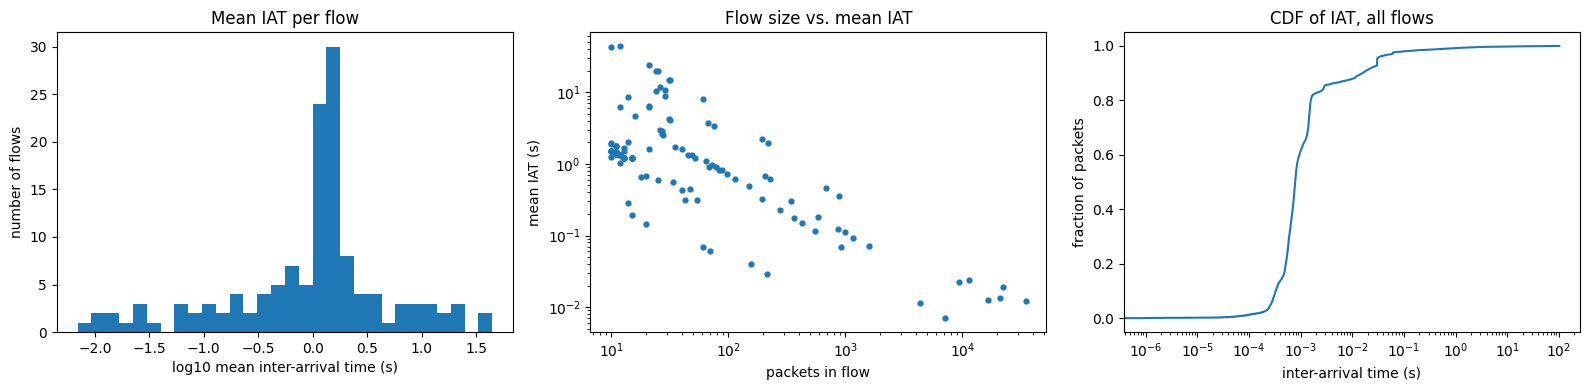

In [7]:
import matplotlib.pyplot as plt

# Statistics of the inter-arrival times, one row per flow
iat_stats = pd.DataFrame(
    [
        {
            "flow": f"{fid[0]}:{fid[2]} -> {fid[1]}:{fid[3]}",
            "dst_port": fid[3],
            "protocol": fid[4],
            "packets": len(x) + 1,
            "iat_mean": x.mean(),
            "iat_std": x.std(),
            "iat_min": x.min(),
            "iat_median": np.median(x),
            "iat_p95": np.percentile(x, 95),
            "iat_max": x.max(),
        }
        for fid, x in iats.items()
    ]
)
display(iat_stats.sort_values("packets", ascending=False).head(10))
display(iat_stats.drop(columns=["dst_port", "protocol"]).describe())

# Plots of per-flow features
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(np.log10(iat_stats["iat_mean"]), bins=30)
ax[0].set_xlabel("log10 mean inter-arrival time (s)")
ax[0].set_ylabel("number of flows")
ax[0].set_title("Mean IAT per flow")

ax[1].scatter(iat_stats["packets"], iat_stats["iat_mean"], s=12)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("packets in flow")
ax[1].set_ylabel("mean IAT (s)")
ax[1].set_title("Flow size vs. mean IAT")

all_iat = np.sort(np.concatenate(list(iats.values())))
ax[2].plot(all_iat, np.arange(1, len(all_iat) + 1) / len(all_iat))
ax[2].set_xscale("log")
ax[2].set_xlabel("inter-arrival time (s)")
ax[2].set_ylabel("fraction of packets")
ax[2].set_title("CDF of IAT, all flows")

plt.tight_layout()
plt.show()

### Other Features and Options

1. Try some of the other features in the `netml` library.

  Here are some of the other possibilities, which can be passed to the library:
  * IAT: A flow is represented as a timeseries of inter-arrival times between packets, i.e., elapsed time in seconds between any two packets in the flow.   
  *  STATS: A flow is represented as a set of statistical quantities. We choose ten of the most common such
statistics in the literature: flow duration, number of packets sent per second, number of bytes
per second, and various statistics on packet sizes within each flow: mean, standard deviation, inter-quartile range,
minimum, and maximum.
  * SIZE: A flow is represented as a timeseries of packet sizes in bytes, with one sample per packet. 
  * SAMP-NUM: A flow is partitioned into small intervals of equal length 𝛿𝑡, and the number of packets in each interval is recorded; thus, a flow is represented as a timeseries of packet counts in small time intervals, with one sample per time interval. Here, 𝛿𝑡 might be viewed as a choice of sampling rate for the timeseries, hence the nomenclature.
  * SAMP-SIZE: A flow is partitioned into time intervals of equal length 𝛿𝑡, and the total packet size (i.e., byte count) in each interval is recorded; thus, a flow is represented as a timeseries of byte counts in small time intervals, with one sample per time interval.
  

In [9]:
# STATS: 12 summary features per flow. Rows are in the same order as `flows` / `fdf`.
stat_cols = ["duration", "pkts_rate", "bytes_rate", "size_mean", "size_std",
             "size_q1", "size_median", "size_q3", "size_min", "size_max",
             "num_pkts", "num_bytes"]

pcap.flow2features("STATS", fft=False, header=False)
assert pcap.fids == [fid for fid, _ in flows]   # same flow order as fdf

stats_df = pd.DataFrame(pcap.features, columns=stat_cols)

# Attach the new features to the flow table (duration/packets/bytes are already there)
fdf_feat = pd.concat(
    [fdf, stats_df.drop(columns=["duration", "num_pkts", "num_bytes"])], axis=1
)
display(fdf_feat.head())

# Fixed-length time-series features, one row per flow.
# (netml names are SAMP_NUM / SAMP_SIZE with underscores.)
features = {}
for feat_type in ["IAT", "SIZE", "SAMP_NUM", "SAMP_SIZE"]:
    pcap.flow2features(feat_type, fft=False, header=False)
    features[feat_type] = pcap.features
    print(f"{feat_type:10s} shape = {pcap.features.shape}")
print(features)

True


,src_ip,dst_ip,src_port,dst_port,protocol,packets,bytes,duration,pkts_rate,bytes_rate,size_mean,size_std,size_q1,size_median,size_q3,size_min,size_max
0,192.168.43.72,172.217.18.195,58443,443,6,12,1072,11.462,1.047,93.530,89.333,49.601,66.000,66.000,69.000,66.000,200.000
1,192.168.43.72,216.58.209.228,58444,443,6,67,5544,248.797,0.269,22.283,82.746,41.922,66.000,66.000,66.000,54.000,200.000
2,192.168.43.72,172.217.18.195,58447,443,6,29,2624,300.745,0.096,8.725,90.483,47.683,66.000,66.000,104.000,54.000,200.000
3,172.217.18.195,192.168.43.72,443,58443,6,10,1387,11.114,0.900,124.793,138.700,59.847,74.000,153.500,200.000,66.000,200.000
4,216.58.209.228,192.168.43.72,443,58444,6,75,12408,248.460,0.302,49.940,165.440,55.638,124.000,200.000,200.000,66.000,200.000


True
IAT        shape = (134, 813)
True
SIZE       shape = (134, 814)
True
SAMP_NUM   shape = (134, 813)
True
SAMP_SIZE  shape = (134, 813)
{'IAT': array([[3.47244024e-01, 7.56025314e-04, 4.64078903e-01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.50138903e-01, 2.55107880e-04, 4.32914972e-01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [5.04117012e-01, 7.49270916e-02, 2.66827822e-01, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [1.75738335e-02, 6.66141510e-04, 1.95138454e-02, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [2.50518322e-02, 1.80006027e-04, 2.07271576e-02, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.27911568e-02, 6.77895546e-03, 1.35493279e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]]), 'SIZE': array([[ 78.,  66., 200., ...,   0.,   0.,   0.],
       [ 78.,  66., 200., ...,   0.,   0.,   0.],
       [ 78.,  66., 20

  
2. One of the challenges with providing packet traces to models involve ensuring that all feature vectors are of the same length. The `netml` libary will do that for you, but there are a number of different ways to solve the problem. What do some of the following options do?  Explore how different settings of the following affect the dimensionality of your resulting feature vector.

 * flow_ptks_thres
 * q_interval

In [10]:
# Re-parse a pcap with different settings and look at the resulting IAT feature matrix.
#  * flow_ptks_thres (PCAP argument): drop flows with fewer packets than this
#  * q_interval (pcap2flows argument): flows are split into sub-flows every `interval`
#    seconds, where interval is the q_interval-quantile of the flow durations. The same
#    quantile of the flow lengths (in packets) sets the feature-vector length; shorter
#    flows are zero-padded and longer ones truncated.
# We use a small pcap here because each combination re-parses the file (a few seconds total).
small_pcap = "/home/frank/ml-systems/docs/notebooks/data/port80.pcap"

rows = []
for thr in [2, 10, 50]:
    for q in [0.5, 0.9, 0.99]:
        p = PCAP(small_pcap, flow_ptks_thres=thr, random_state=42, verbose=0)
        p.pcap2flows(q_interval=q)
        p.flow2features("IAT", fft=False, header=False)
        rows.append({
            "flow_ptks_thres": thr,
            "q_interval": q,
            "num_flows": len(p.flows),
            "feature_dim": p.features.shape[1],
        })

pd.DataFrame(rows)

,flow_ptks_thres,q_interval,num_flows,feature_dim
0,2,0.500,159,5
1,2,0.900,148,30
2,2,0.990,119,232
3,10,0.500,35,22
4,10,0.900,35,142
5,10,0.990,39,243
6,50,0.500,6,184
7,50,0.900,8,239
8,50,0.990,8,248


**What the two options do** (on `port80.pcap`, IAT features):

* `flow_ptks_thres` drops flows with fewer packets than the threshold, so it mainly changes the number of rows (flows). Going from 2 to 50 cuts the flows from 159 to 6 (at `q_interval=0.5`), because most flows in this trace are short.
* `q_interval` picks the quantile used (a) to split long flows into sub-flows (every `interval` seconds) and (b) to choose the feature-vector length from the flow lengths. Low `q_interval` gives short vectors (5 values at q=0.5, threshold 2) but cuts flows into many sub-flows. High `q_interval` keeps flows whole but makes vectors much longer (232 at q=0.99), mostly zero-padding for the short flows.

## Thought Questions

What other features might you want to extract from packet captures that are not provided by the `netml` library?